In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## EDA

In [2]:
folder = Path('california')

months = [f"2024{m:02d}" for m in range(1, 7)]   # 2024-01 to 2024-06

files = []
for m in months:
    matches = list(folder.glob(f"CRMLSSold{m}*.csv"))
    if not matches:
        print(f"Missing: {m}")
    files.extend(matches)

print(len(files), "files found")

df = pd.concat(
    (pd.read_csv(f, low_memory=False).assign(source_file=f.name) for f in files),
    ignore_index=True,
)
print(df.shape)

6 files found
(136614, 83)


In [3]:
df.columns

Index(['Flooring', 'ViewYN', 'WaterfrontYN', 'BasementYN', 'PoolPrivateYN',
       'OriginalListPrice', 'ListingKey', 'ListAgentEmail', 'CloseDate',
       'ClosePrice', 'ListAgentFirstName', 'ListAgentLastName', 'Latitude',
       'Longitude', 'UnparsedAddress', 'PropertyType', 'LivingArea',
       'ListPrice', 'DaysOnMarket', 'ListOfficeName', 'BuyerOfficeName',
       'CoListOfficeName', 'ListAgentFullName', 'CoListAgentFirstName',
       'CoListAgentLastName', 'BuyerAgentMlsId', 'BuyerAgentFirstName',
       'BuyerAgentLastName', 'FireplacesTotal', 'AssociationFeeFrequency',
       'AboveGradeFinishedArea', 'ListingKeyNumeric', 'MLSAreaMajor',
       'TaxAnnualAmount', 'CountyOrParish', 'MlsStatus', 'ElementarySchool',
       'AttachedGarageYN', 'ParkingTotal', 'BuilderName', 'PropertySubType',
       'LotSizeAcres', 'SubdivisionName', 'BuyerOfficeAOR', 'YearBuilt',
       'BuyerAgencyCompensationType', 'StreetNumberNumeric', 'ListingId',
       'BathroomsTotalInteger', 'City', 'Bu

In [4]:
df_filtered = df[(df['PropertyType'] =='Residential') & (df['PropertySubType'] == 'SingleFamilyResidence')]
df_filtered.shape

(68641, 83)

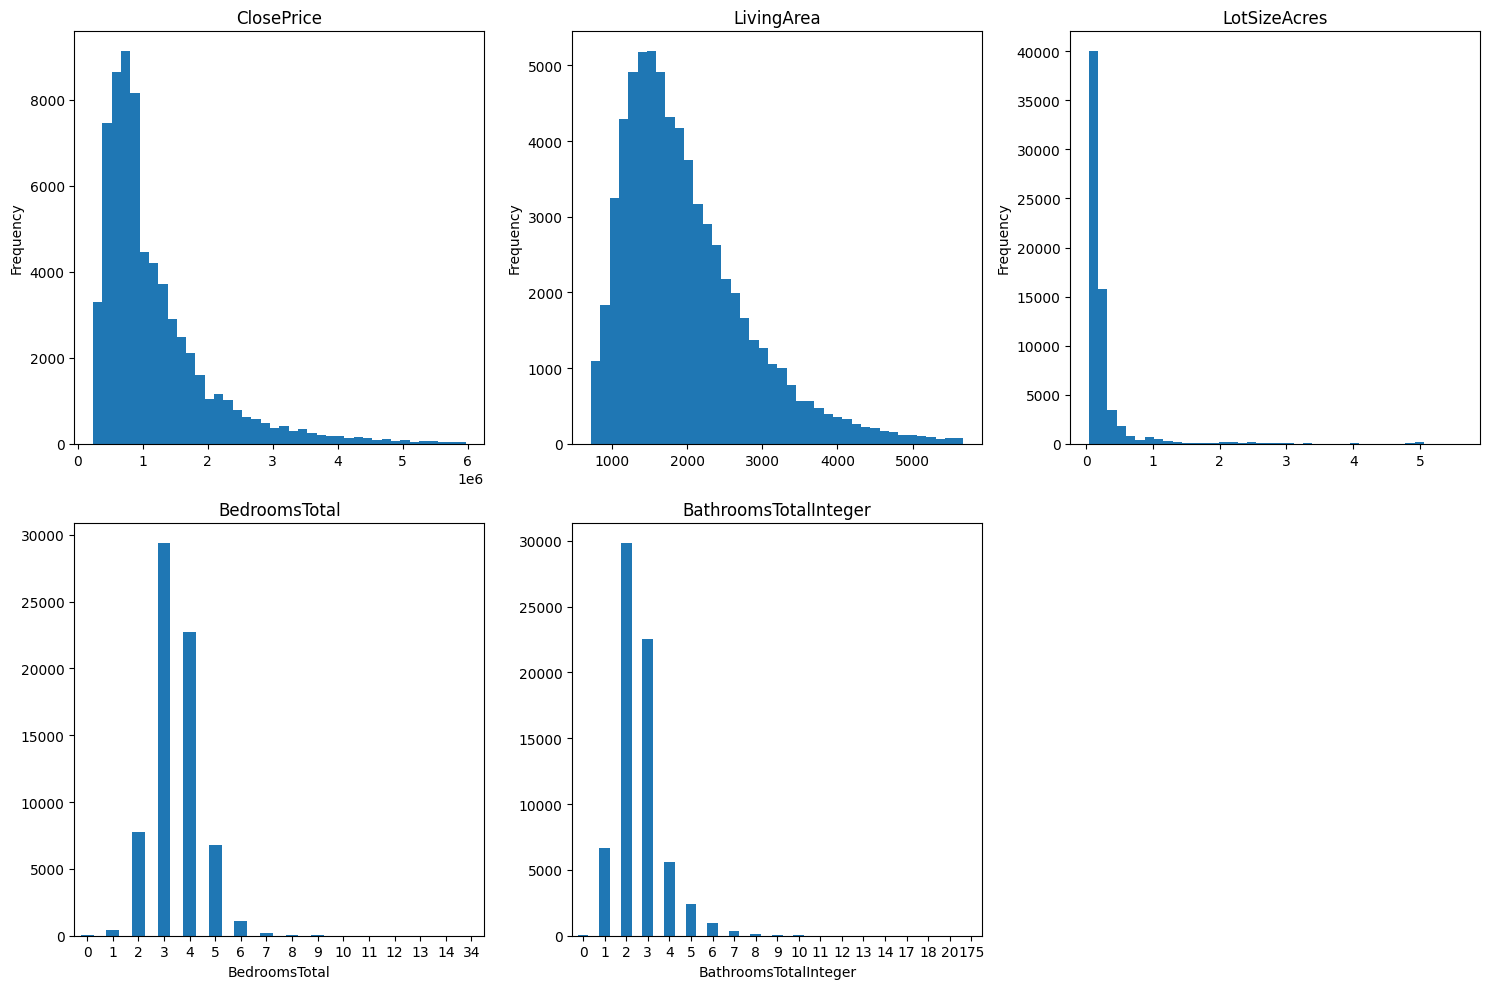

In [5]:
fig, axes = plt.subplots(figsize=(15, 10), nrows=2, ncols=3)
hist_cols = ['ClosePrice', 'LivingArea', 'LotSizeAcres']
int_cols = ['BedroomsTotal', 'BathroomsTotalInteger']

for ax, prop in zip(axes.flat, hist_cols):
    s = df_filtered[prop].dropna()
    lo, hi = s.quantile([0.01, 0.99])
    s[(s >= lo) & (s <= hi)].plot(kind='hist', bins=40, ax=ax, title=prop)

for ax, prop in zip(axes.flat[len(hist_cols):], int_cols):
    counts = (df_filtered[prop].dropna().astype(int)
              .value_counts().sort_index())
    counts.plot(kind='bar', ax=ax, title=prop)
    ax.tick_params(axis='x', rotation=0)

axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [6]:
properties = hist_cols + int_cols

# Lets see if we can make the distribution of these properties more normal by applying a log transformation
for prop in properties:
    df_filtered[f'log_{prop}'] = df_filtered[prop].apply(lambda x: np.log(x) if x > 0 else np.nan)

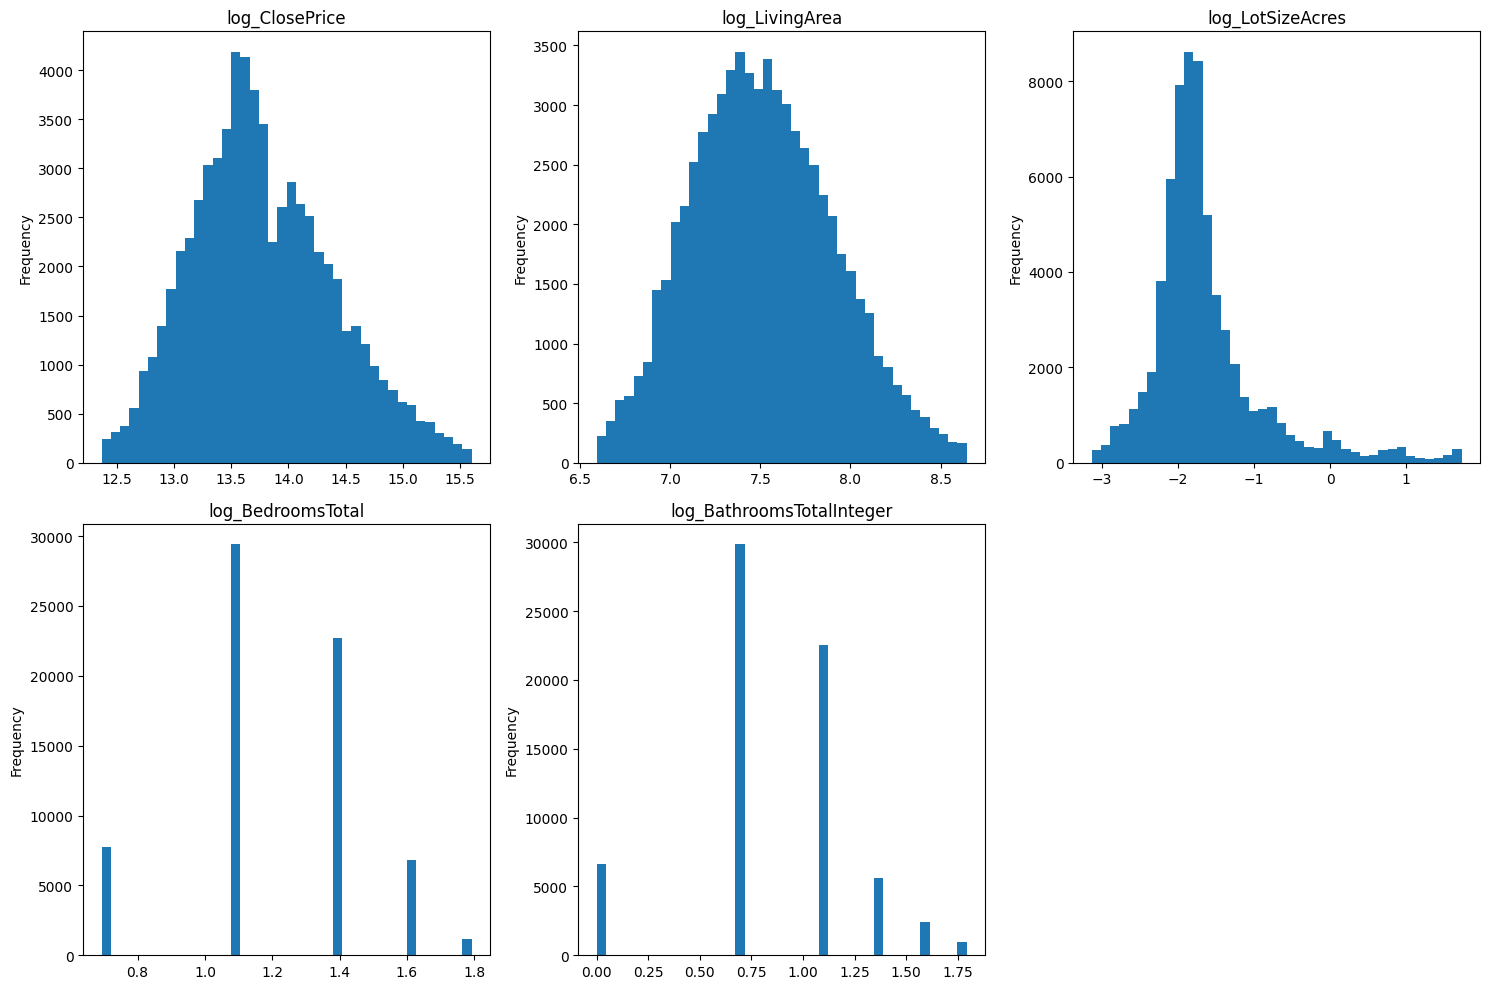

In [7]:
fig, axes = plt.subplots(figsize=(15, 10), nrows=2, ncols=3)

for ax, prop in zip(axes.flat, properties):
    s = df_filtered[f'log_{prop}'].dropna()
    lo, hi = s.quantile([0.01, 0.99])
    s[(s >= lo) & (s <= hi)].plot(kind='hist', bins=40, ax=ax, title=f'log_{prop}')

axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

In [8]:
print(properties)

for prop in properties:
    summary = df_filtered[prop].describe().T
    summary['nulls'] = df_filtered[prop].isna().sum()
    summary['skew'] = df_filtered[prop].skew()
    print(str(summary) + '\n----------------------------------------------')
    

['ClosePrice', 'LivingArea', 'LotSizeAcres', 'BedroomsTotal', 'BathroomsTotalInteger']
count    6.864000e+04
mean     1.257151e+06
std      1.330793e+06
min      3.450000e+02
25%      6.150000e+05
50%      8.950000e+05
75%      1.460000e+06
max      6.280000e+07
nulls    1.000000e+00
skew     8.632369e+00
Name: ClosePrice, dtype: float64
----------------------------------------------
count    68605.000000
mean      2027.036120
std       1027.672641
min          0.000000
25%       1367.000000
50%       1798.000000
75%       2414.000000
max      22897.000000
nulls       36.000000
skew         2.987381
Name: LivingArea, dtype: float64
----------------------------------------------
count    6.747500e+04
mean     1.205122e+02
std      3.007063e+04
min      0.000000e+00
25%      1.300000e-01
50%      1.657000e-01
75%      2.354000e-01
max      7.810698e+06
nulls    1.166000e+03
skew     2.597161e+02
Name: LotSizeAcres, dtype: float64
----------------------------------------------
count    68

## Preprocessing
ClosePrice, LivingArea, LotSizeAcres are more normally distributed after the log transformation. BedroomsTotal and BathroomsTotalInteger are still not normally distributed, but they are discrete variables and may not be expected to be normally distributed. \
LotSizeAcres has many missing values, but also is very leptokurtic, so we can fill the NAs with the median

In [9]:
TARGET = 'ClosePrice'
LOG_COLS = ['LivingArea', 'LotSizeAcres']
RAW_COLS = ['BedroomsTotal', 'BathroomsTotalInteger']
KEEP = ['CloseDate', TARGET] + LOG_COLS + RAW_COLS
WANT = ['LivingArea', 'LotSizeAcres', 'BedroomsTotal', 'BathroomsTotalInteger', 'YearBuilt', 'Stories', 'Levels',
          'GarageSpaces', 'ParkingTotal', 'FireplacesTotal', 'PoolPrivateYN', 'ViewYN', 'WaterfrontYN', 'BasementYN', 'NewConstructionYN']

In [10]:
def clean_rows(df):
    '''
    Drop rows with null values in any of the columns in KEEP, 
    except for LotSizeAcres which will be filled with the median value. 
    Also drop rows where ClosePrice or LivingArea are less than or equal to zero.
    '''
    df = df[(df['PropertyType'] =='Residential') & (df['PropertySubType'] == 'SingleFamilyResidence')].copy()
    df = df[KEEP]
    df = df.dropna(subset=[c for c in KEEP if c != 'LotSizeAcres'])
    return df[(df[TARGET] > 0) & (df['LivingArea'] > 0)] 

def time_based_split(df, X=1):
    df = df.copy()
    df['CloseDate'] = pd.to_datetime(df['CloseDate'], format='%Y-%m-%d')
    month = df['CloseDate'].dt.to_period('M')
    test_month = month.max()
    train_start = test_month - X
    train_df = df[(month >= train_start) & (month < test_month)].copy()
    test_df = df[month == test_month].copy()
    return train_df, test_df

def safe_log(x):
    x = np.asarray(x, dtype=float)
    return np.log(np.where(x > 0, x, np.nan))


log_branch = make_pipeline(
    FunctionTransformer(safe_log, feature_names_out='one-to-one'),
    SimpleImputer(strategy='median'),
)

preprocessor = ColumnTransformer(
    transformers=[
        ('log', log_branch, LOG_COLS),
        ('raw', 'passthrough', RAW_COLS),
    ],
    remainder='drop',                    # drops CloseDate and the target from the features
    verbose_feature_names_out=False,
).set_output(transform='pandas')


def build_pipeline(model):
    return Pipeline([
        ('prep', preprocessor),
        ('model', TransformedTargetRegressor(
            regressor=model, func=np.log, inverse_func=np.exp)),   # log_ClosePrice in, dollars out
    ])


In [11]:
from sklearn.base import clone

df_clean = clean_rows(df)

processor = clone(preprocessor)
df_prep = processor.fit_transform(df_clean) # log & fill 

# rename the logged columns
df_prep = df_prep.rename(columns={c: f'log_{c}' for c in LOG_COLS})

# add back log_closeprice and date
output = df_prep.copy()
output['log_ClosePrice'] = np.log(df_clean[TARGET])
output.insert(0, 'CloseDate', df_clean['CloseDate'])

output.to_csv('cleaned_data.csv', index=False)
output.head()

,CloseDate,log_LivingArea,log_LotSizeAcres,BedroomsTotal,BathroomsTotalInteger,log_ClosePrice
5,2024-01-05,7.587817,-1.796973,4.0,4.0,13.610943
9,2024-01-05,7.587817,-1.796973,4.0,4.0,13.604790
28,2024-01-02,8.225771,-1.356347,4.0,4.0,14.557448
29,2024-01-22,7.649693,0.536493,3.0,0.0,14.483340
31,2024-01-31,7.800573,-1.609438,4.0,3.0,14.665661


## Baseline Model

In [12]:
train_df, test_df = time_based_split(df_clean, X=3)

pipe = build_pipeline(LinearRegression())
pipe.fit(train_df.drop(columns=TARGET), train_df[TARGET])
preds = pipe.predict(test_df.drop(columns=TARGET))

# Evaluate
print("R²:", r2_score(test_df[TARGET], preds))
print("MSE:", mean_squared_error(test_df[TARGET], preds))

# Inspect what the model learned
print("Coefficients:", pipe.named_steps['model'].regressor_.coef_)
print("Intercept:", pipe.named_steps['model'].regressor_.intercept_)

R²: 0.38261399284944664
MSE: 1035109460951.9244
Coefficients: [ 0.66306629 -0.06514511 -0.04035471  0.16127616]
Intercept: 8.433301477467111
